# Keystroke verification: from the idea to a method comparison

**The question:** someone types a password. Is it really *the owner*, or an impostor?

**The idea:** every person types with their own rhythm. We measure that rhythm as numbers, learn the owner's
"normal rhythm" from past typing, and check how *far* a new attempt is from it.
Close → accept. Far → reject.

**Data:** CMU Keystroke Benchmark: 51 people typed the same password (`.tie5Roanl`) 400 times each.
Download `DSL-StrongPasswordData.csv` from <https://www.cs.cmu.edu/~keystroke/> and put it in `experiments/data/`.

**How this notebook is organised**

| Part | What you do |
|---|---|
| **Part 1** (Steps 1–10) | Understand the whole idea using **one user**, one small step at a time |
| **Part 2** (Steps 11–14) | Turn it into a fair test and compare **7 methods** on all **51 users** |
| **Part 3** | Read the results, limits, and what to try next |

Run the cells one by one with **Shift+Enter** and read the note under each output.

# Part 1 · Understand the idea with one user

## Step 1 · Import the tools
* `numpy` for fast maths on lists of numbers
* `pandas` for tables
* `matplotlib` for plots
* `OneClassSVM` (from scikit-learn) is used later, in Part 2

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

## Step 2 · Load the data
One row = **one typing attempt**. The timing columns are in seconds:

* `H.x` = **hold time**: how long key `x` stayed pressed
* `DD.x.y` = time from pressing key `x` to pressing key `y`
* `UD.x.y` = time from *releasing* `x` to pressing `y`

In [2]:
df = pd.read_csv("data/DSL-StrongPasswordData.csv")
print("table size (rows, columns):", df.shape)
df.head(3)

table size (rows, columns): (20400, 34)


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945


20,400 rows = 51 people × 400 attempts. The first three columns say *who* typed and *which* attempt it was.
All the other columns are timing numbers.

## Step 3 · Choose the columns that describe typing rhythm
Everything except `subject`, `sessionIndex` and `rep` is a timing number. We call these our **features**.

In [3]:
feature_cols = [c for c in df.columns if c not in ["subject", "sessionIndex", "rep"]]
print("number of features:", len(feature_cols))
print(feature_cols[:6], "...")

number of features: 31
['H.period', 'DD.period.t', 'UD.period.t', 'H.t', 'DD.t.i', 'UD.t.i'] ...


**Do people really type differently?** Here is the hold time of the letter `t` for three people. Each colour is one person.

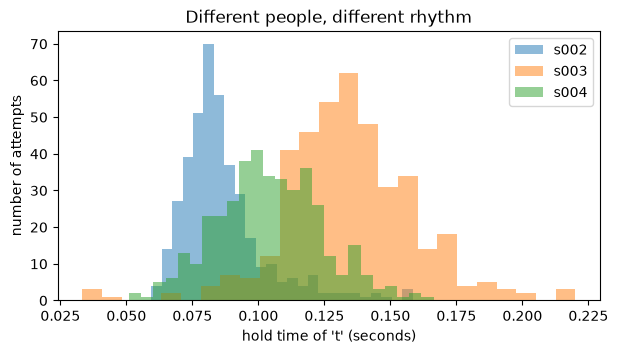

In [4]:
plt.figure(figsize=(7, 3.5))
for person in df.subject.unique()[:3]:
    plt.hist(df[df.subject == person]["H.t"], bins=25, alpha=0.5, label=person)
plt.xlabel("hold time of 't' (seconds)")
plt.ylabel("number of attempts")
plt.legend()
plt.title("Different people, different rhythm")
plt.show()

The colours are in different places. That difference is what the system will use.

## Step 4 · Pick one person (the "owner") and split their attempts
* First **200** attempts → used to *learn* the owner's rhythm (training)
* Last **200** attempts → used to *test*. The system has never seen these.

The test attempts are from later sessions, so this is realistic: the system learns today, the owner types again later.

In [5]:
owner = "s002"
owner_attempts = df[df.subject == owner][feature_cols].values   # .values = plain table of numbers
train = owner_attempts[:200]
test_genuine = owner_attempts[200:]
print("train:", train.shape, "| genuine test:", test_genuine.shape)   # (attempts, 31 numbers)

train: (200, 31) | genuine test: (200, 31)


## Step 5 · Build the owner's "fingerprint" (profile)
For each of the 31 numbers we keep two things from the 200 training attempts:
* the **average** (what is normal for this person)
* the **spread** = standard deviation (how much they normally vary)

In [6]:
profile_mean = train.mean(axis=0)   # axis=0 → average down the rows: one value per column
profile_std = train.std(axis=0)

pd.DataFrame({"average": profile_mean, "spread": profile_std}, index=feature_cols).head(5).round(3)

,average,spread
H.period,0.106,0.014
DD.period.t,0.184,0.084
UD.period.t,0.078,0.083
H.t,0.085,0.010
DD.t.i,0.156,0.035


Example: if `H.period` has average 0.10 s and spread 0.02 s, the owner normally holds that key about 0.08–0.12 seconds.
A hold time of 0.30 s would be unusual for them.

## Step 6 · A score: "how far is this attempt from the owner's normal?"
For one number: `(value − average) / spread` says how many "spreads" away it is. This is a **z-score**.
We take the size of that for all 31 numbers and average them. That gives **one distance per attempt**:
* small distance (around 1 or less) → looks like the owner
* big distance → looks different

In [7]:
def typing_distance(attempts):
    z = (attempts - profile_mean) / profile_std     # how many spreads away, for each number
    return np.abs(z).mean(axis=1)                   # ignore the sign, average over the 31 numbers

print("distances of 3 genuine attempts:", typing_distance(test_genuine[:3]).round(2))

distances of 3 genuine attempts: [0.94 0.86 1.26]


## Step 7 · Make impostor attempts and compare
Impostors = the **first 5 attempts of each of the other 50 people** (250 attempts).
We score both groups. We expect genuine attempts to get *smaller* distances.

impostor attempts: (250, 31)
average distance, genuine : 0.94
average distance, impostor: 2.13


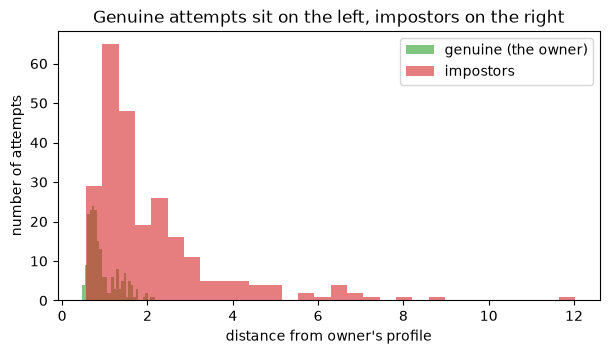

In [8]:
other_people = df[df.subject != owner]
impostor_attempts = other_people.groupby("subject").head(5)[feature_cols].values
print("impostor attempts:", impostor_attempts.shape)

genuine_scores = typing_distance(test_genuine)
impostor_scores = typing_distance(impostor_attempts)
print("average distance, genuine :", genuine_scores.mean().round(2))
print("average distance, impostor:", impostor_scores.mean().round(2))

plt.figure(figsize=(7, 3.5))
plt.hist(genuine_scores, bins=30, alpha=0.6, label="genuine (the owner)", color="tab:green")
plt.hist(impostor_scores, bins=30, alpha=0.6, label="impostors", color="tab:red")
plt.xlabel("distance from owner's profile")
plt.ylabel("number of attempts")
plt.legend()
plt.title("Genuine attempts sit on the left, impostors on the right")
plt.show()

The two groups are mostly separated, but they **overlap** in the middle. That overlap is where mistakes will happen.

## Step 8 · Make a decision with a threshold
Rule: **accept if distance ≤ threshold, otherwise reject.** Two kinds of mistakes can happen:

* **FRR** (false reject rate): the real owner is rejected 😠
* **FAR** (false accept rate): an impostor is accepted 😱

In [9]:
threshold = 1.5

FRR = (genuine_scores > threshold).mean()     # share of genuine attempts that were rejected
FAR = (impostor_scores <= threshold).mean()   # share of impostor attempts that were accepted
print(f"threshold = {threshold}  →  FRR = {FRR:.1%} (owner rejected),  FAR = {FAR:.1%} (impostor accepted)")

threshold = 1.5  →  FRR = 9.0% (owner rejected),  FAR = 47.2% (impostor accepted)


**Try it:** change `threshold` to 1.0, then 2.0, and run again. A **stricter** (smaller) threshold lowers FAR but raises FRR.
You cannot make both zero.

## Step 9 · Try many thresholds and draw the trade-off

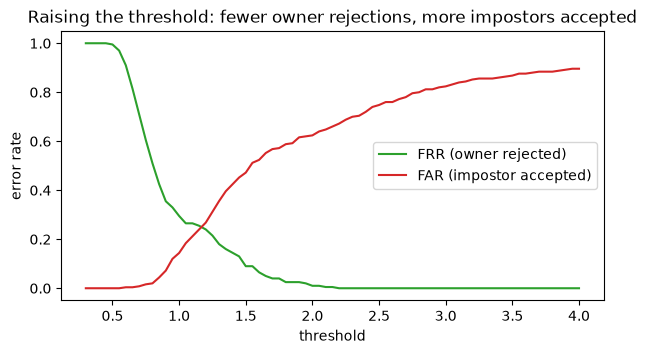

In [10]:
thresholds = np.linspace(0.3, 4, 75)
FRR_curve = [(genuine_scores > t).mean() for t in thresholds]
FAR_curve = [(impostor_scores <= t).mean() for t in thresholds]

plt.figure(figsize=(7, 3.5))
plt.plot(thresholds, FRR_curve, label="FRR (owner rejected)", color="tab:green")
plt.plot(thresholds, FAR_curve, label="FAR (impostor accepted)", color="tab:red")
plt.xlabel("threshold")
plt.ylabel("error rate")
plt.legend()
plt.title("Raising the threshold: fewer owner rejections, more impostors accepted")
plt.show()

## Step 10 · The Equal Error Rate (EER)
The **EER** is the error at the threshold where FAR and FRR are equal. It is one number that says how good a method is:
**lower is better** (0% = perfect, 50% = random guessing).

In [11]:
gap = np.abs(np.array(FAR_curve) - np.array(FRR_curve))   # how different the two errors are
best = gap.argmin()                                       # position where they are closest
eer_one_user = (FAR_curve[best] + FRR_curve[best]) / 2
print(f"best threshold = {thresholds[best]:.2f}")
print(f"EER for user {owner} = {eer_one_user:.1%}")

best threshold = 1.15
EER for user s002 = 24.8%


This one user (`s002`) is a fairly **hard** case. Part 2 checks everybody.

# Part 2 · Compare 7 methods on all 51 users

In Part 1 we used **one** way to measure "distance" (the z-score distance). There are other ways.
Which one works best? To find out, we need two things:
1. a **fair test**, the same for every method, and
2. every method written the **same simple way**.

## Step 11 · Package the fair test
**The test, for each user in turn** (same as Part 1):

| Set | Samples |
|---|---|
| Train | the user's first 200 attempts |
| Genuine test | the user's last 200 attempts |
| Impostor test | the first 5 attempts of each of the other 50 users (250) |

**The error numbers:** `eer_and_frr` tries every score as a threshold and finds the EER (like Step 10, but exact).
It also reports **FRR at FAR ≤ 1%**: *"if we allow only 1 impostor in 100 through, how many real owners get rejected?"*

In [12]:
users = sorted(df.subject.unique())

def get_user_data(user):
    attempts = df[df.subject == user][feature_cols].values
    impostors = df[df.subject != user].groupby("subject").head(5)[feature_cols].values
    return attempts[:200], attempts[200:], impostors      # train, genuine test, impostor test

data_by_user = {u: get_user_data(u) for u in users}


def eer_and_frr(genuine, impostor):
    thr = np.sort(np.concatenate([genuine, impostor]))        # try every score as a threshold
    frr = (genuine[None, :] > thr[:, None]).mean(axis=1)      # FRR at each threshold
    far = (impostor[None, :] <= thr[:, None]).mean(axis=1)    # FAR at each threshold
    k = np.abs(far - frr).argmin()                            # where FAR and FRR are closest
    eer = (far[k] + frr[k]) / 2
    safe = far <= 0.01                                        # thresholds that keep FAR ≤ 1%
    frr_at_far1 = frr[safe].min() if safe.any() else 1.0
    return eer, frr_at_far1

**Check the error function on small examples where we know the answer**, so we can trust it.

In [13]:
# perfectly separated scores → no errors
assert eer_and_frr(np.array([0.1, 0.2, 0.3]), np.array([1.0, 2.0, 3.0]))[0] == 0.0
# reversed scores (genuine looks worse than impostor) → everything wrong
assert eer_and_frr(np.array([5.0, 6.0, 7.0]), np.array([0.1, 0.2, 0.3]))[0] == 1.0
# worked by hand: genuine 1..10, impostor 6..15 → at threshold 7: FRR 0.3, FAR 0.2; at 8: FRR 0.2, FAR 0.3 → EER 0.25
assert abs(eer_and_frr(np.arange(1.0, 11), np.arange(6.0, 16))[0] - 0.25) < 1e-9
print("error function checks passed")

error function checks passed


## Step 12 · The 7 methods
Every method has the same shape: **learn from the 200 training attempts → return a scoring function**
(higher score = more like an impostor). So they are easy to swap and compare.

| Method | Idea in one line |
|---|---|
| **Euclidean** | straight-line distance to the owner's average |
| **Manhattan** | add up the absolute differences to the average |
| **Scaled Manhattan** | Manhattan, with each number divided by the owner's own typical variation |
| **Z-score distance** | what we built in Part 1 (average of |z|) |
| **Mahalanobis** | distance that also uses how the numbers move *together* |
| **TrueTestAuth profile** | z-score idea used in our app: root-mean-square of z, with a **minimum spread** (7% of the average) so very steady typists are not over-strict |
| **One-class SVM** | a machine-learning model that learns a boundary around the owner's normal attempts |

In [14]:
def euclidean(train):
    mean = train.mean(axis=0)
    return lambda X: np.sqrt(((X - mean) ** 2).sum(axis=1))

def manhattan(train):
    mean = train.mean(axis=0)
    return lambda X: np.abs(X - mean).sum(axis=1)

def scaled_manhattan(train):
    mean = train.mean(axis=0)
    typical_variation = np.abs(train - mean).mean(axis=0)      # average distance from the average
    return lambda X: (np.abs(X - mean) / typical_variation).sum(axis=1)

def zscore_distance(train):                                     # the method from Part 1
    mean, std = train.mean(axis=0), train.std(axis=0)
    return lambda X: np.abs((X - mean) / std).mean(axis=1)

def mahalanobis(train):
    mean = train.mean(axis=0)
    inv_cov = np.linalg.pinv(np.cov(train, rowvar=False))       # how the 31 numbers vary together
    return lambda X: np.sqrt(np.einsum("ij,jk,ik->i", X - mean, inv_cov, X - mean))

def trueTestAuth_profile(train, min_spread=0.07):
    mean, std = train.mean(axis=0), train.std(axis=0, ddof=1)
    spread = np.maximum(std, min_spread * np.abs(mean))         # never smaller than 7% of the average
    return lambda X: np.sqrt((((X - mean) / spread) ** 2).mean(axis=1))

def one_class_svm(train):
    scaler = StandardScaler().fit(train)
    svm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.1).fit(scaler.transform(train))
    return lambda X: -svm.decision_function(scaler.transform(X))   # minus: higher = more suspicious


methods = {
    "Euclidean": euclidean,
    "Manhattan": manhattan,
    "Scaled Manhattan": scaled_manhattan,
    "Z-score distance": zscore_distance,
    "Mahalanobis": mahalanobis,
    "TrueTestAuth profile": trueTestAuth_profile,
    "One-class SVM": one_class_svm,
}

*(Note on the `Mahalanobis` line: `einsum` is just a short way to write "for every attempt, compute `d · inv_cov · d`".
You do not need to understand it to follow the rest.)*

## Step 13 · Run every method on every user
For each method and each of the 51 users: learn from the training attempts, score the test attempts, and record the EER.

In [15]:
rows = []
for name, method in methods.items():
    for user in users:
        train_u, genuine_u, impostor_u = data_by_user[user]
        score = method(train_u)                                   # learn the owner's profile
        eer, frr_at_far1 = eer_and_frr(score(genuine_u), score(impostor_u))
        rows.append({"method": name, "user": user, "EER": eer, "FRR at FAR 1%": frr_at_far1})

results = pd.DataFrame(rows)
print("rows in results:", len(results), "(7 methods × 51 users)")

rows in results: 357 (7 methods × 51 users)


## Step 14 · The results
Average over the 51 users. **Lower is better.**

In [16]:
summary = (results.groupby("method")[["EER", "FRR at FAR 1%"]].mean()
           .sort_values("EER") * 100).round(2)
summary.columns = ["average EER (%)", "FRR when FAR is 1% (%)"]
summary

,average EER (%),FRR when FAR is 1% (%)
method,,
Z-score distance,9.31,42.04
Scaled Manhattan,9.60,43.31
TrueTestAuth profile,10.44,37.84
One-class SVM,10.67,48.76
Mahalanobis,11.00,35.34
Manhattan,15.29,68.57
Euclidean,17.05,75.60


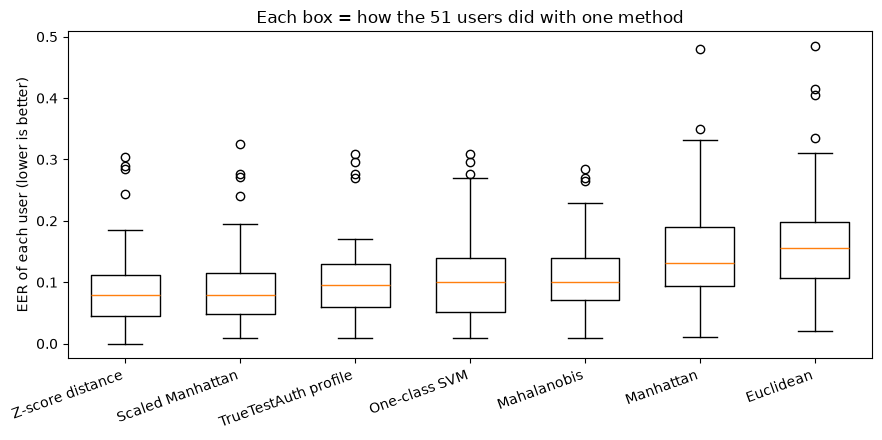

saved to C:\Users\tripa\OneDrive\Desktop\IIITR B.TECH\GEN-AI\Projects\TrueTestAuth-main\TrueTestAuth-main\experiments\results


In [17]:
order = list(summary.index)
plt.figure(figsize=(9, 4.5))
plt.boxplot([results[results.method == m].EER for m in order], widths=0.6)
plt.xticks(range(1, len(order) + 1), order, rotation=20, ha="right")
plt.ylabel("EER of each user (lower is better)")
plt.title("Each box = how the 51 users did with one method")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/results_eer_boxplot.png", dpi=140)
plt.show()

results.to_csv("results/results_per_user.csv", index=False)
summary.to_csv("results/results_summary.csv")
print("saved to", os.path.abspath("results"))

# Part 3 · What the results tell us

**What we see in the table and the boxplot**

* **Dividing by the user's own variation helps a lot.** Z-score distance (9.3%), Scaled Manhattan (9.6%) and the TrueTestAuth profile (10.4%) all do better than Manhattan (15.3%) and Euclidean (17.1%). Euclidean and Manhattan treat every number equally, even though some numbers naturally vary much more than others.
* **The idea used in our app is competitive.** The TrueTestAuth profile is in the top group. It is also better than Scaled Manhattan on the strict test (FRR when FAR is 1%): 37.8% against 43.3%. Mahalanobis is best on that strict test (35.3%).
* **Users are very different.** In the boxplot, some users have an EER near 0% and a few are above 30%. The average hides this.
* **The classic results look right.** Scaled Manhattan, Mahalanobis, Manhattan and Euclidean are close to the numbers published in the CMU paper (about 9.6%, 11.0%, 15.3% and 17.1%, as far as we remember), which is a good sign that the test is set up correctly.

**Why this is not good enough yet**

* An EER of about 9–10% means roughly 1 decision in 10 is wrong.
* When we are strict (allow only 1 impostor in 100), **35–50% of real owners are rejected**. A real exam cannot work like that.
* This gap is the research question for the neural methods (Siamese, LSTM, Transformer).

**Limits to remember**

* CMU is a **fixed password** typed in a lab. It cannot test free typing, like exam answers.
* CMU gives only summary timings per key pair, not raw key events. Sequence models need a dataset with raw events.
* The 31 CMU numbers are different from the 13 numbers in our app, so the *TrueTestAuth profile* row tests the **idea**, not the exact app code.

## Summary
1. Typing rhythm can be measured as numbers (hold times and gaps between keys).
2. From a person's past typing we build a **profile** (average and spread of every number).
3. A new attempt gets a **distance** from that profile. A **threshold** turns it into accept / reject.
4. The threshold trades **FAR** against **FRR**. **EER** is one number for comparing methods.
5. Methods are compared fairly: same split, same impostors, same metric, averaged over all users.

**Where this connects to our app:** `ml_model.py` uses the *TrueTestAuth profile* idea, then turns the distance into a 0–1 confidence.

**Next steps**
* Add a neural method (for example a **Siamese network**) as one more function in `methods`. It plugs into Steps 13–14 unchanged.
* Try a raw-sequence **LSTM / Transformer** on a dataset with raw key events (such as the Aalto 136M keystrokes data).
* Collect real data from classmates through the app and run the same test on it.